# Rama B: fluorescencia azul con 822 nm y 852 nm

El PMT lateral cuenta la fluorescencia azul (7P → 6S) de la cascada que sale de 8S1/2. Hay tres tipos de barrido, todos con una onda triangular de 20 mHz, 200 ms de exposición y la celda a 80 °C:

1. **Solo el 822 (45 mW), barriendo λ822:** pico de absorción de dos fotones 6S F=4 → 8S F=4.
2. **Solo el 852, barriendo λ852** a 7 potencias entre 0.2 y 14.4 mW: la línea D2 desde 6S F=4.
3. **El 822 fijo (46 mW, desintonía nominal 0 MHz) y el 852 barrido**, a las mismas potencias: efecto de la semilla sobre la población de 8S.

**Nombre de archivo:** `<láser barrido>-[<desintonía del fijo>]-<P barrido>-[<P fijo>]-<frec. barrido>-<exposición>-<T celda>.txt`, donde los campos entre corchetes son opcionales.
**Columnas:** col 0 no se usa, col 1 λ del láser barrido (nm), col 2 cuentas/s del PMT, col 3 ν del láser barrido (THz).

Las desintonías se dan respecto a frecuencias absolutas tabuladas, no respecto a una referencia redondeada:

- **822:** $\nu_{822} - \nu_{TP}/2$, con $\nu_{TP}$ la transición de dos fotones 6S1/2 F=4 → 8S1/2 F=4.
- **852:** $\nu_{852} - \nu(6S_{1/2}\,F{=}4 \to 6P_{3/2}\,F'{=}5)$. Con la convención del README de la rama ($\Delta_3 = \omega_{ba} - \omega_3$), este eje es $-\Delta_3$ para la componente F′=5.

In [1]:
import sys
sys.path.append('../..')  # carpeta raíz del repositorio, donde está constants.py
import os, glob
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from scipy.ndimage import uniform_filter1d

from constants import c, kB, cte

C_LIGHT = c*1e-3  # nm*THz
BASE = '.'

# Estructura hiperfina (THz). 6S y 6P3/2: Steck, "Cesium D Line Data"; 8S1/2: A = 219.125 MHz (Fendel et al. 2007)
HF_6S_F4 = 4.021776399375e-3
HF_6P = {5: 263.81e-6, 4: 12.815e-6, 3: -188.4885e-6}
HF_8S_F4 = 7/4 * 219.125e-6

NU_852 = cte['nu_ba[Hz]']*1e-12 - HF_6S_F4 + HF_6P[5]          # 6S F=4 -> 6P3/2 F'=5
NU_822 = (cte['nu_ca[Hz]']*1e-12 - HF_6S_F4 + HF_8S_F4) / 2    # mitad de 6S F=4 -> 8S F=4
DET_FP = {F: (HF_6P[F] - HF_6P[5])*1e6 for F in (5, 4, 3)}      # F' respecto a F'=5 (MHz)

def doppler_fwhm(nu, T_C):
    # FWHM Doppler (MHz) de un haz a frecuencia nu (THz), átomos a T_C (°C)
    return nu*1e6*np.sqrt(8*kB*(T_C + 273.15)*np.log(2) / (cte['m_Cs[kg]']*c**2))

print(f'ν(F=4→F′=5) = {NU_852:.6f} THz  (λ = {C_LIGHT/NU_852:.6f} nm)')
print(f'ν_TP/2      = {NU_822:.6f} THz  (λ = {C_LIGHT/NU_822:.6f} nm)')
print('F′ respecto a F′=5 (MHz):', {F: round(v, 1) for F, v in DET_FP.items()})

# Colores: azul/naranja/aqua para series, tonos de un solo azul para la potencia
C1, C2, C3, INK, GRID = '#2a78d6', '#eb6834', '#1baf7a', '#0b0b0b', '#8a8984'
plt.rcParams.update({'axes.grid': True, 'grid.alpha': 0.3, 'axes.spines.top': False, 'axes.spines.right': False})

ν(F=4→F′=5) = 351.721961 THz  (λ = 852.356383 nm)
ν_TP/2      = 364.503080 THz  (λ = 822.468929 nm)
F′ respecto a F′=5 (MHz): {5: 0.0, 4: -251.0, 3: -452.3}


In [2]:
def parse_name(path):
    # <láser>-[<desint. fijo>]-<P barrido>-[<P fijo>]-<frec>-<exp>-<T>.txt
    f = os.path.basename(path)[:-4].split('-')
    def mW(s):
        return float(s[:-3])*1e-3 if s.endswith('muW') else float(s[:-2])
    meta = dict(laser=int(f[0]), T=float(f[-1][:-1]), t_exp=float(f[-2][:-2]), f_bar=float(f[-3][:-3]),
                det_fijo=None, P_fijo=None)
    if len(f) == 7:
        meta.update(det_fijo=float(f[1][:-3]), P=mW(f[2]), P_fijo=mW(f[3]))
    else:
        meta.update(P=mW(f[1]))
    return meta

def load(path):
    # Descarta filas sin lectura válida del láser barrido y las de 0 cuentas
    # (primera lectura de cada archivo y huecos aislados del QuTau)
    meta = parse_name(path)
    d = np.loadtxt(path)
    k = (np.abs(d[:, 1] - meta['laser']) < 1) & (d[:, 2] > 0)
    ref = NU_822 if meta['laser'] == 822 else NU_852
    return meta, dict(lam=d[k, 1], A=d[k, 2], det=(d[k, 3] - ref)*1e6, n_desc=int((~k).sum()))

def ramps(lam, w=9, dist=40):
    # Índices de cada rampa del barrido triangular, cortando en los extremos de lambda
    s = uniform_filter1d(lam, w)
    t = np.sort(np.r_[find_peaks(s, distance=dist)[0], find_peaks(-s, distance=dist)[0]])
    edges = np.r_[0, t, len(lam)]
    return [np.arange(a, b) for a, b in zip(edges[:-1], edges[1:]) if b - a > 5]

def average(x, y, segs, bin_w=10.0):
    # Promedia todas las rampas en bins de ancho bin_w (MHz): media y desviación estándar
    idx = np.concatenate(segs)
    xb = np.floor(x[idx]/bin_w)*bin_w + bin_w/2
    ux = np.unique(xb)
    m = np.array([y[idx][xb == u].mean() for u in ux])
    s = np.array([y[idx][xb == u].std() for u in ux])
    return ux, m, s

def scan(path, bin_w=10.0):
    meta, d = load(path)
    segs = ramps(d['lam'])
    x, m, s = average(d['det'], d['A'], segs, bin_w)
    return meta, d, segs, x, m, s

def label(meta):
    return f"{meta['P']*1e3:.0f} µW" if meta['P'] < 1 else f"{meta['P']:g} mW"

def mark_Fp(ax):
    # Líneas verticales en las transiciones F=4 → F'=3, 4, 5 (átomos con v_z = 0)
    for F, x0 in DET_FP.items():
        ax.axvline(x0, ls='--', lw=0.8, color=GRID)
        ax.annotate(f"F′={F}", (x0, 1), xycoords=('data', 'axes fraction'), xytext=(2, -10),
                    textcoords='offset points', fontsize=8, color=GRID)

files = sorted(f for f in glob.glob(os.path.join(BASE, 'data', '*.txt')) if 'readme' not in f.lower())
files = [f for f in files if parse_name(f)['T'] == 80]  # las tomas a 60 y 70 °C se analizan en fluorescencia_temperatura.ipynb
F822 = [f for f in files if parse_name(f)['laser'] == 822]
F852 = sorted([f for f in files if parse_name(f)['laser'] == 852 and parse_name(f)['P_fijo'] is None],
              key=lambda f: parse_name(f)['P'])
FCOMB = sorted([f for f in files if parse_name(f)['laser'] == 852 and parse_name(f)['P_fijo'] is not None],
               key=lambda f: parse_name(f)['P'])

print(f"{'archivo':46s} {'barre':>5s} {'P (mW)':>7s} {'fijo':>12s} {'filas':>6s} {'desc.':>6s} {'rampas':>6s} {'rango (MHz)':>15s}")
for f in F822 + F852 + FCOMB:
    meta, d = load(f)
    fijo = f"{meta['P_fijo']:g} mW, {meta['det_fijo']:g} MHz" if meta['P_fijo'] else '—'
    print(f"{os.path.basename(f):46s} {meta['laser']:5d} {meta['P']:7.3f} {fijo:>12s} {len(d['A']) + d['n_desc']:6d} "
          f"{d['n_desc']:6d} {len(ramps(d['lam'])):6d} {d['det'].min():7.0f}…{d['det'].max():.0f}")

archivo                                        barre  P (mW)         fijo  filas  desc. rampas     rango (MHz)
822-45mW-20mHz-200ms-80C.txt                     822  45.000            —    656      1      6   -2331…1539
852-200muW-20mHz-200ms-80C.txt                   852   0.200            —    568      3      5    -863…771
852-503muW-20mHz-200ms-80C.txt                   852   0.503            —   1249      1     11    -817…840
852-1mW-20mHz-200ms-80C.txt                      852   1.000            —    855      2      8    -760…884
852-3.5mW-20mHz-200ms-80C.txt                    852   3.500            —    583      1      6    -785…846
852-5mW-20mHz-200ms-80C.txt                      852   5.000            —    829      1      8    -788…882
852-10.1mW-20mHz-200ms-80C.txt                   852  10.100            —    704      2      7    -887…764
852-14.42mW-20mHz-200ms-80C.txt                  852  14.420            —    727      2      7    -667…977
852-0MHz-200muW-46mW-20mHz-200ms

## 1. Barrido del 822 solo

El 822 viaja en un solo haz, así que los dos fotones llegan copropagantes y la resonancia de dos fotones queda ensanchada por Doppler. En la frecuencia del láser, el ancho esperado es el Doppler a 822 nm: $\nu_{822}\sqrt{8k_BT\ln 2/mc^2}$. El ajuste es una gaussiana más línea base.

Las rampas de subida y de bajada se ajustan por separado para medir el corrimiento que produce la exposición de 200 ms. El PMT integra durante la exposición, mientras que el medidor de onda da un solo valor de λ.

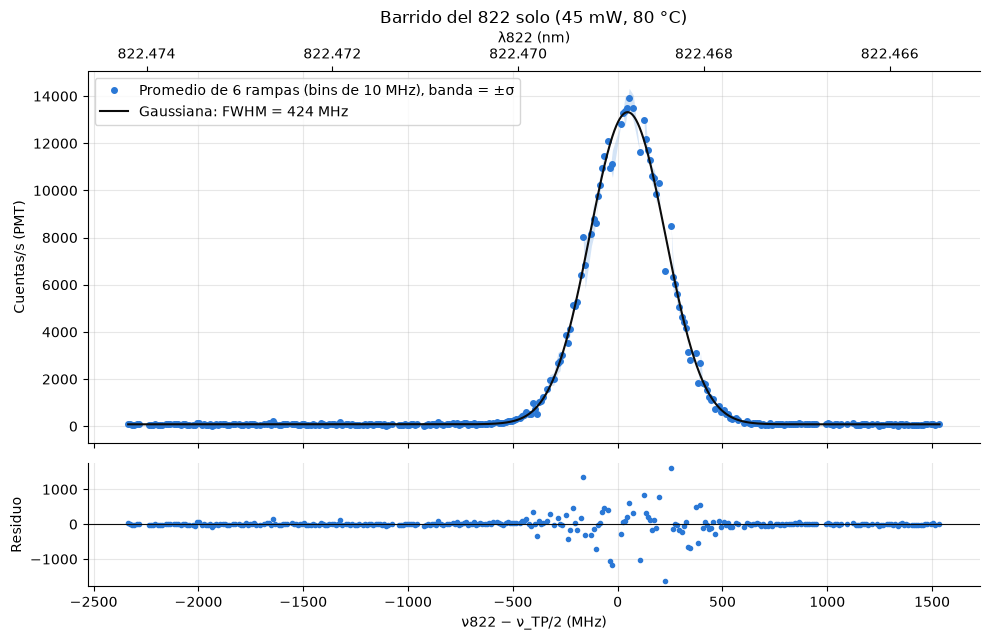

Centro: 47.3 ± 0.9 MHz  (λ0 = 822.468822 nm)
FWHM:   424.4 ± 2.2 MHz   (Doppler a 80 °C: 425.6 MHz)
Altura: 13239 ± 62 cuentas/s sobre una línea base de 82 ± 15
Centro con ν subiendo: 56 MHz, bajando: 35 MHz → diferencia 21 MHz (el promedio de ambas direcciones la cancela)


In [3]:
def gauss(x, c0, x0, s, a):
    return c0 + a*np.exp(-(x - x0)**2 / (2*s**2))

def fit_gauss(x, y):
    k = np.argmax(uniform_filter1d(y, 5))
    popt, pcov = curve_fit(gauss, x, y, p0=[np.percentile(y, 5), x[k], 150, y[k]], maxfev=20000)
    return popt, np.sqrt(np.diag(pcov))

meta, d, segs, x, m, s = scan(F822[0])
popt, perr = fit_gauss(x, m)
fwhm_D = doppler_fwhm(NU_822, meta['T'])

fig, (ax, axr) = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True, gridspec_kw=dict(height_ratios=[3, 1]))
ax.fill_between(x, m - s, m + s, color=C1, alpha=0.2, lw=0)
ax.plot(x, m, 'o', ms=4, color=C1, label=f'Promedio de {len(segs)} rampas (bins de 10 MHz), banda = ±σ')
xx = np.linspace(x.min(), x.max(), 2000)
ax.plot(xx, gauss(xx, *popt), '-', color=INK, lw=1.5, label=f'Gaussiana: FWHM = {2.3548*abs(popt[2]):.0f} MHz')
ax.set_ylabel('Cuentas/s (PMT)')
ax.set_title(f"Barrido del 822 solo ({meta['P']:g} mW, {meta['T']:g} °C)")
ax.legend()
def det2lam(d_):
    with np.errstate(divide='ignore'):
        return C_LIGHT/(NU_822 + d_*1e-6)
def lam2det(l):
    with np.errstate(divide='ignore'):
        return (C_LIGHT/l - NU_822)*1e6
sec = ax.secondary_xaxis('top', functions=(det2lam, lam2det))
sec.set_xlabel('λ822 (nm)')
sec.ticklabel_format(useOffset=False)
axr.plot(x, m - gauss(x, *popt), 'o', ms=3, color=C1)
axr.axhline(0, color=INK, lw=0.8)
axr.set_ylabel('Residuo')
axr.set_xlabel('ν822 − ν_TP/2 (MHz)')
fig.tight_layout()
plt.show()

print(f'Centro: {popt[1]:.1f} ± {perr[1]:.1f} MHz  (λ0 = {C_LIGHT/(NU_822 + popt[1]*1e-6):.6f} nm)')
print(f'FWHM:   {2.3548*abs(popt[2]):.1f} ± {2.3548*perr[2]:.1f} MHz   (Doppler a {meta["T"]:g} °C: {fwhm_D:.1f} MHz)')
print(f'Altura: {popt[3]:.0f} ± {perr[3]:.0f} cuentas/s sobre una línea base de {popt[0]:.0f} ± {perr[0]:.0f}')

# Corrimiento entre rampas de subida y de bajada (se omite la primera rampa, que está incompleta)
x0s = {+1: [], -1: []}
for sg in segs[1:]:
    p, _ = fit_gauss(d['det'][sg], d['A'][sg])
    x0s[int(np.sign(d['det'][sg][-1] - d['det'][sg][0]))].append(p[1])
up, dn = np.mean(x0s[+1]), np.mean(x0s[-1])
print(f'Centro con ν subiendo: {up:.0f} MHz, bajando: {dn:.0f} MHz → diferencia {up - dn:.0f} MHz '
      f'(el promedio de ambas direcciones la cancela)')
X0_822 = popt[1]

## 2. Barrido del 852 solo

A baja potencia el perfil tiene **dos jorobas con un hueco en el centro de la línea**. Es autoabsorción: la celda a 80 °C es ópticamente gruesa en la D2, y el haz se absorbe antes de llegar a la región que ve el PMT, justo en las frecuencias donde la absorción es más fuerte. Si la fluorescencia vista es proporcional a la luz absorbida en esa región,

$$S(\nu) = c + a\, g(\nu)\, e^{-b\, g(\nu)}, \qquad g(\nu) = \sum_{F'=3,4,5} w_{F'}\, \exp\!\left[-\frac{(\nu - \nu_0 - \delta_{F'})^2}{2\sigma^2}\right],$$

donde $\delta_{F'}$ son los corrimientos tabulados de F′ respecto a F′=5, y $w_{F'} \propto (7/72,\ 7/24,\ 11/18)$ son las intensidades relativas de F=4 → F′=3, 4, 5, normalizadas a $w_5 = 1$.
Los parámetros libres son la línea base $c$, el corrimiento $\nu_0$ (que incluye el error absoluto del medidor de onda), el ancho Doppler $\sigma$, la amplitud $a$ y la profundidad óptica efectiva $b$ hasta la región observada. Con $b \to 0$ el modelo vuelve a ser un perfil Doppler ordinario.

Al subir la potencia la transición se satura, el medio se vuelve transparente ($b \to 0$) y la línea se ensancha por potencia.

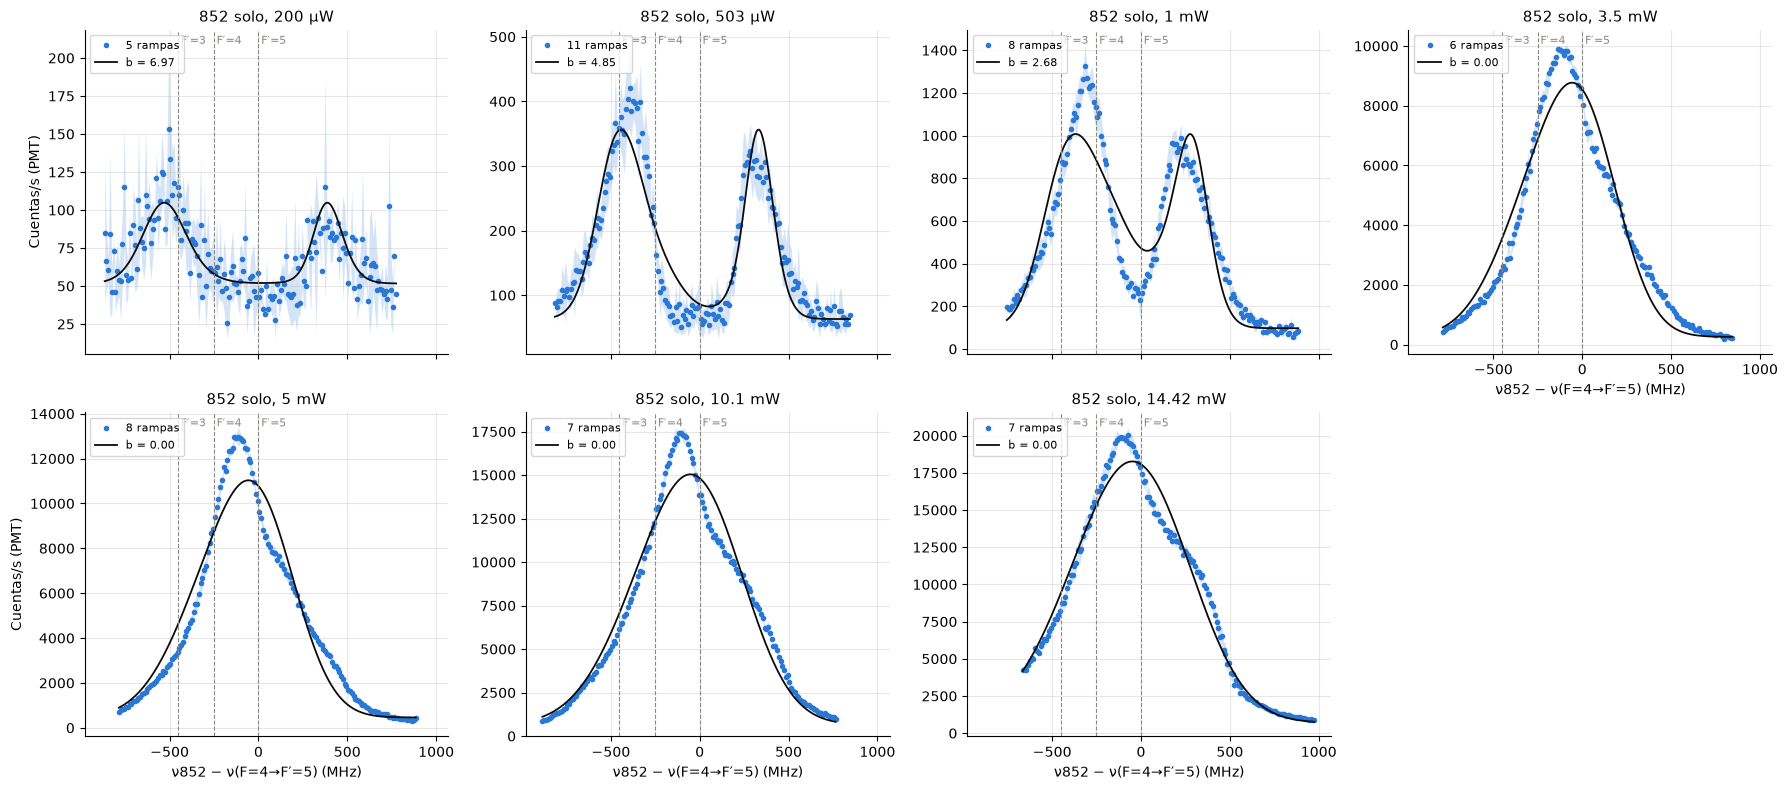

 P (mW)    ν0 (MHz)   FWHM (MHz)           b  máx (c/s)   base
  0.200     73 ± 8     375 ± 24    6.97 ± 1.21        153     52
  0.503     84 ± 4     327 ± 10    4.85 ± 0.29        421     63
  1.000     72 ± 5     342 ± 12    2.68 ± 0.14       1328     97
  3.500     15 ± 4     474 ± 37    0.00 ± 0.12       9890    258
  5.000     19 ± 5     493 ± 43    0.00 ± 0.13      12981    459
 10.100     37 ± 4     594 ± 58    0.00 ± 0.13      17419    661
 14.420     47 ± 3     677 ± 48    0.00 ± 0.10      20057    700
FWHM Doppler a 852 nm y 80 °C: 411 MHz


In [4]:
W_FP = np.array([11/18, 7/24, 7/72]); W_FP /= W_FP[0]
D_FP = np.array([DET_FP[5], DET_FP[4], DET_FP[3]])

def g852(x, x0, s):
    return sum(w*np.exp(-(x - x0 - dd)**2 / (2*s**2)) for w, dd in zip(W_FP, D_FP))

def selfabs(x, c0, x0, s, a, b):
    g = g852(x, x0, s)
    return c0 + a*g*np.exp(-b*g)

def fit_selfabs(x, y):
    # Varias semillas de b: el ajuste con b grande y con b ~ 0 tiene mínimos locales distintos
    best = None
    for b0 in [0.1, 1, 3, 6, 10]:
        try:
            popt, pcov = curve_fit(selfabs, x, y, p0=[np.percentile(y, 2), 0, 175, y.max(), b0],
                                   bounds=([-np.inf, -1000, 30, 0, 0], [np.inf, 1000, 600, np.inf, 50]), maxfev=20000)
        except RuntimeError:
            continue
        r = np.sum((y - selfabs(x, *popt))**2)
        if best is None or r < best[0]:
            best = (r, popt, np.sqrt(np.diag(pcov)))
    return best[1], best[2]

res852 = []
fig, axs = plt.subplots(2, 4, figsize=(18, 8), sharex=True)
for ax, f in zip(axs.flat, F852):
    meta, d, segs, x, m, s = scan(f)
    popt, perr = fit_selfabs(x, m)
    ax.fill_between(x, m - s, m + s, color=C1, alpha=0.2, lw=0)
    ax.plot(x, m, 'o', ms=3, color=C1, label=f'{len(segs)} rampas')
    xx = np.linspace(x.min(), x.max(), 2000)
    ax.plot(xx, selfabs(xx, *popt), '-', color=INK, lw=1.3, label=f'b = {popt[4]:.2f}')
    mark_Fp(ax)
    ax.set_title(f"852 solo, {label(meta)}", fontsize=11)
    ax.legend(fontsize=8, loc='upper left')
    res852.append(dict(P=meta['P'], x0=popt[1], ex0=perr[1], fwhm=2.3548*popt[2], efwhm=2.3548*perr[2],
                       a=popt[3], b=popt[4], eb=perr[4], c0=popt[0], peak=m.max(),
                       area=np.trapezoid(m - popt[0], x), name=os.path.basename(f)))
axs.flat[-1].axis('off')
for ax in axs[:, 0]:
    ax.set_ylabel('Cuentas/s (PMT)')
for ax in axs[-1]:
    ax.set_xlabel('ν852 − ν(F=4→F′=5) (MHz)')
axs[0, -1].xaxis.set_tick_params(labelbottom=True)
axs[0, -1].set_xlabel('ν852 − ν(F=4→F′=5) (MHz)')
fig.tight_layout()
plt.show()

fwhm_D852 = doppler_fwhm(NU_852, 80)
print(f"{'P (mW)':>7s} {'ν0 (MHz)':>11s} {'FWHM (MHz)':>12s} {'b':>11s} {'máx (c/s)':>10s} {'base':>6s}")
for r in res852:
    print(f"{r['P']:7.3f} {r['x0']:6.0f} ± {r['ex0']:<3.0f} {r['fwhm']:5.0f} ± {r['efwhm']:<4.0f} {r['b']:5.2f} ± {r['eb']:<4.2f} "
          f"{r['peak']:10.0f} {r['c0']:6.0f}")
print(f'FWHM Doppler a 852 nm y 80 °C: {fwhm_D852:.0f} MHz')

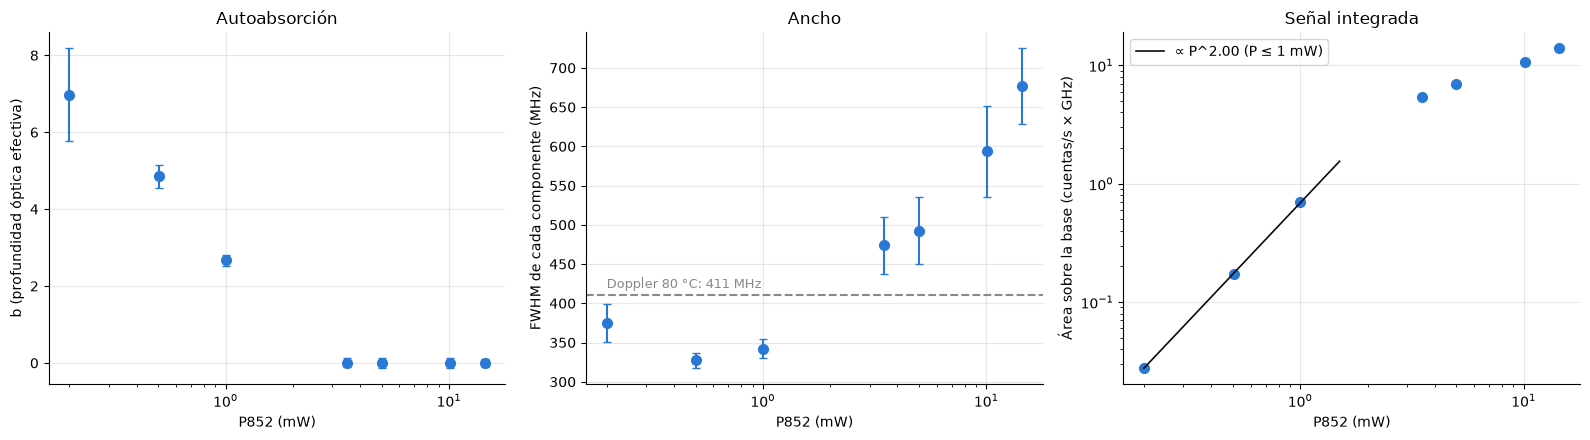

Exponente de la señal integrada para P ≤ 1 mW: 2.00


In [5]:
P = np.array([r['P'] for r in res852])
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
blues = plt.cm.Blues(np.linspace(0.45, 0.95, len(P)))

ax = axs[0]
ax.errorbar(P, [r['b'] for r in res852], yerr=[r['eb'] for r in res852], fmt='o', ms=7, color=C1, capsize=3)
ax.set_xscale('log')
ax.set_xlabel('P852 (mW)')
ax.set_ylabel('b (profundidad óptica efectiva)')
ax.set_title('Autoabsorción')

ax = axs[1]
ax.errorbar(P, [r['fwhm'] for r in res852], yerr=[r['efwhm'] for r in res852], fmt='o', ms=7, color=C1, capsize=3)
ax.axhline(fwhm_D852, ls='--', color=GRID)
ax.annotate(f'Doppler 80 °C: {fwhm_D852:.0f} MHz', (P.min(), fwhm_D852), xytext=(0, 5), textcoords='offset points',
            fontsize=9, color=GRID)
ax.set_xscale('log')
ax.set_xlabel('P852 (mW)')
ax.set_ylabel('FWHM de cada componente (MHz)')
ax.set_title('Ancho')

ax = axs[2]
area = np.array([r['area'] for r in res852])*1e-6
lo = P <= 1.0
k_area, lnA = np.polyfit(np.log(P[lo]), np.log(area[lo]), 1)
ax.loglog(P, area, 'o', ms=7, color=C1)
pp = np.geomspace(P.min(), 1.5, 50)
ax.loglog(pp, np.exp(lnA)*pp**k_area, '-', color=INK, lw=1.2, label=f'∝ P^{k_area:.2f} (P ≤ 1 mW)')
ax.set_xlabel('P852 (mW)')
ax.set_ylabel('Área sobre la base (cuentas/s × GHz)')
ax.set_title('Señal integrada')
ax.legend()
fig.tight_layout()
plt.show()
print(f'Exponente de la señal integrada para P ≤ 1 mW: {k_area:.2f}')

**Lectura.**

- **Baja potencia:** $b$ cae de ≈ 7 a ≈ 3 entre 0.2 y 1 mW. El modelo da la forma de dos jorobas, pero no la reproduce en detalle: en los datos el hueco central es más plano y los flancos más abruptos, y el residuo rms es ≈ 10 % del máximo. Por eso el ancho ajustado (330–375 MHz, algo por debajo del Doppler de 411 MHz) depende del modelo. Si se deja libre un exponente, $S \propto (g\,e^{-bg})^p$, el rms baja apenas ≈ 10 % y los parámetros quedan muy correlacionados, así que no se usa.
- **Desde 3.5 mW:** el ajuste da $b = 0$, es decir, la transición se blanquea por saturación. El ancho crece muy por encima del Doppler por ensanchamiento de potencia, y queda un hombro a ≈ +300 MHz que el perfil gaussiano no reproduce.
- **Señal integrada:** crece como ≈ $P^2$ a baja potencia. Este exponente es empírico y mezcla dos efectos: el blanqueamiento del medio (que $b$ baje con $P$) y el orden del proceso que lleva átomos a 7P sin el 822. Por eso no identifica el mecanismo por sí solo.

## 3. Barrido del 852 con el 822 fijo

Con el 822 fijo en el máximo de dos fotones solo contribuyen a la línea base los átomos de la clase $v_z \approx 0$. Cuando el 852 es resonante con F=4 → F′ **para esa misma clase**, los saca de F=4 y la fluorescencia de dos fotones baja. Eso produce valles sub-Doppler en las frecuencias absolutas de la D2.

- **F′=3 y F′=4:** decaen también a F=3, que no es resonante con el 822. Hay bombeo óptico y los valles son profundos.
- **F′=5:** es cíclica, sin bombeo, y el efecto es pequeño.

A baja potencia (≤ 1 mW) el ajuste es una línea base lineal menos dos lorentzianas. La semilla del valle más profundo sale de la señal, y la del segundo se pone a +201 MHz (F′=3 → F′=4). Si el segundo valle no resulta significativo (< 3σ), se ajusta solo el primero.
A partir de 3.5 mW domina la fluorescencia que produce el 852 por sí solo (sección 2), así que esos barridos no se ajustan y se comparan en la sección 4.

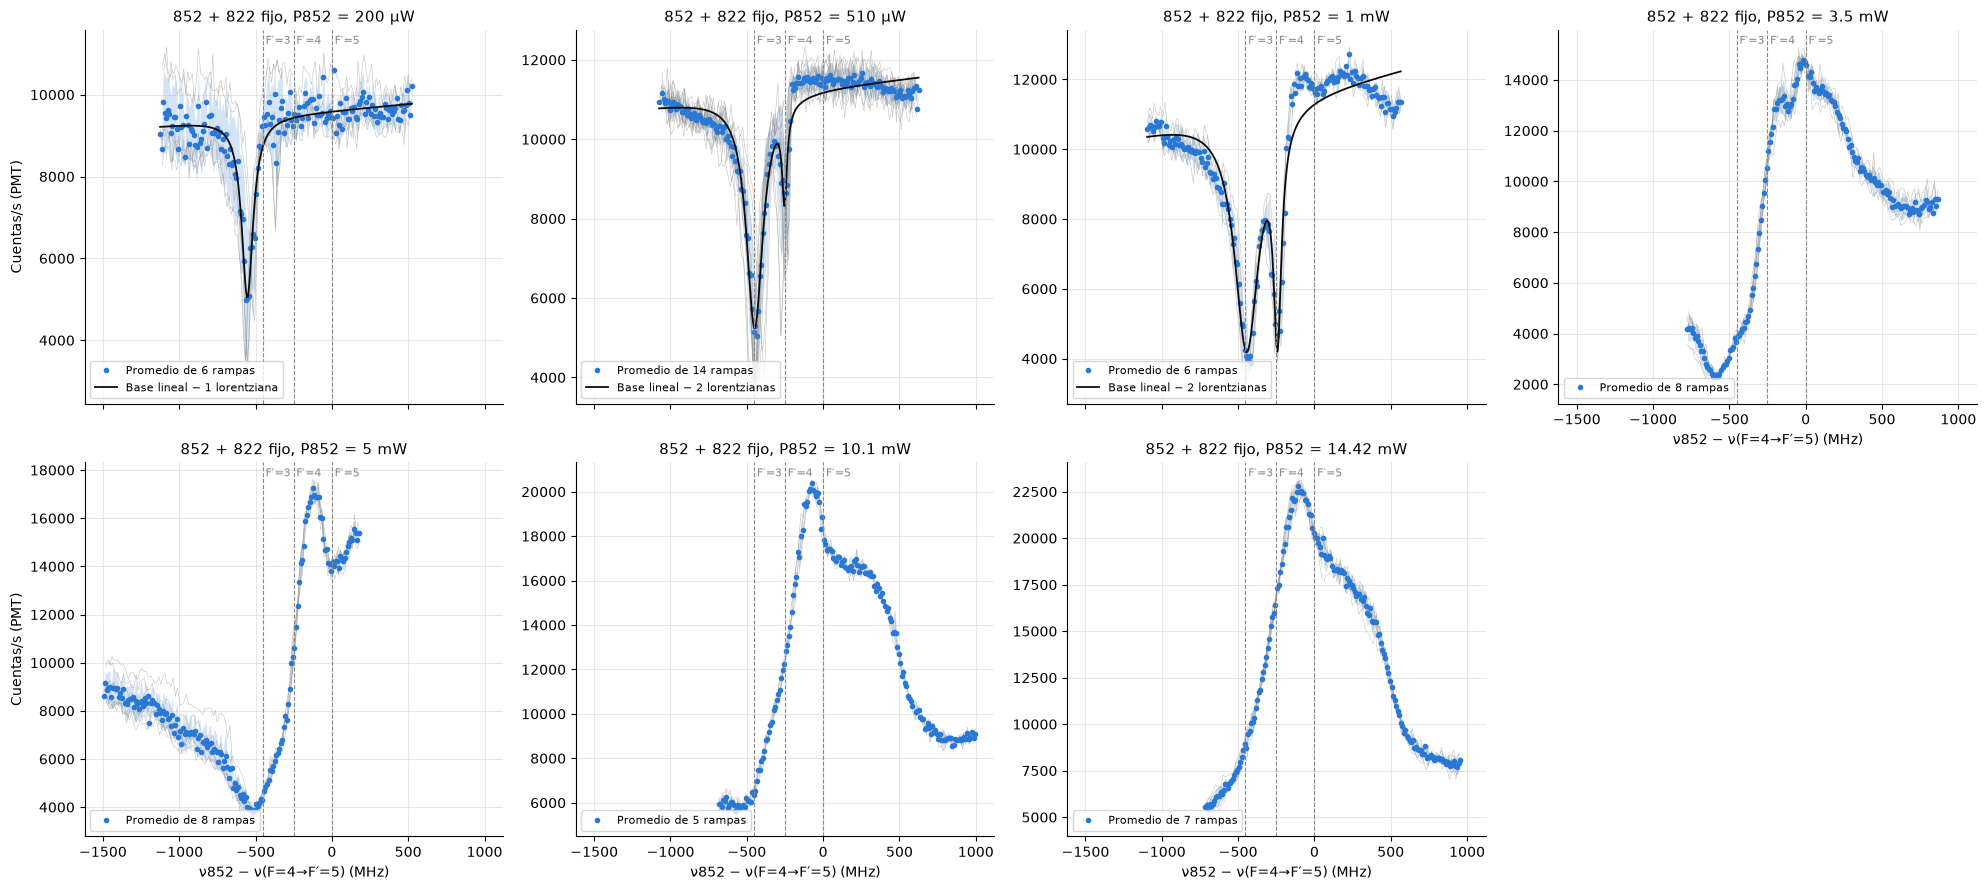

 P (mW) |  F′=3: x0 (MHz)       FWHM       prof. |  F′=4: x0 (MHz)       FWHM       prof. |  x4 − x3 (MHz)
  0.200 |    -554 ± 2       91 ± 6    4380 ± 179  |               no resuelto               | 
  0.510 |    -449 ± 2      132 ± 5    5848 ± 137  |    -253 ± 2       39 ± 6    2285 ± 251  |   195 ± 3
  1.000 |    -444 ± 3      195 ± 12   6892 ± 210  |    -242 ± 2       62 ± 6    5922 ± 370  |   202 ± 4
Tabulado: F′=3 en -452.3 MHz, F′=4 en -251.0 MHz, separación 201.3 MHz


In [6]:
def lorentz(x, x0, g, a):
    return a*(g/2)**2 / ((x - x0)**2 + (g/2)**2)

def dips(x, c0, c1, *p):
    return c0 + c1*x*1e-3 - sum(lorentz(x, *p[i:i + 3]) for i in range(0, len(p), 3))

def fit_dips(x, y):
    # Valle más profundo (F'=3) + otro a +201 MHz (F'=4). Si el segundo no es significativo (< 3σ), se ajusta uno solo
    c0 = np.percentile(y, 90)
    k = np.argmin(uniform_filter1d(y, 3))
    p0 = [c0, 0, x[k], 50, c0 - y[k], x[k] + DET_FP[4] - DET_FP[3], 50, 0.3*(c0 - y[k])]
    try:
        popt, pcov = curve_fit(dips, x, y, p0=p0, maxfev=20000)
        perr = np.sqrt(np.diag(pcov))
        j = np.argmax(popt[[2, 5]]) * 3 + 2   # valle de mayor frecuencia
        if popt[j + 2] > 3*perr[j + 2] and abs(popt[j + 1]) < 300:
            return popt, perr
    except RuntimeError:
        pass
    popt, pcov = curve_fit(dips, x, y, p0=p0[:5], maxfev=20000)
    return popt, np.sqrt(np.diag(pcov))

def dip_params(popt, perr):
    # Diccionario {x3, ex3, g3, ...} ordenando los valles por frecuencia; F'=4 queda en NaN si no se resolvió
    js = sorted(range(2, len(popt), 3), key=lambda j: popt[j])
    out = {}
    for F, j in zip((3, 4), js + [None]):
        for k, i in (('x', 0), ('g', 1), ('a', 2)):
            out[f'{k}{F}'] = np.nan if j is None else abs(popt[j + i]) if k == 'g' else popt[j + i]
            out[f'e{k}{F}'] = np.nan if j is None else perr[j + i]
    return out

resdip = []
fig, axs = plt.subplots(2, 4, figsize=(20, 9), sharex=True)
for ax, f in zip(axs.flat, FCOMB):
    meta, d, segs, x, m, s = scan(f)
    for sg in segs:
        ax.plot(d['det'][sg], d['A'][sg], '-', lw=0.4, color=GRID, alpha=0.5)
    ax.fill_between(x, m - s, m + s, color=C1, alpha=0.2, lw=0)
    ax.plot(x, m, 'o', ms=3, color=C1, label=f'Promedio de {len(segs)} rampas')
    if meta['P'] <= 1.0:
        popt, perr = fit_dips(x, m)
        xx = np.linspace(x.min(), x.max(), 2000)
        nd = (len(popt) - 2)//3
        ax.plot(xx, dips(xx, *popt), '-', color=INK, lw=1.3,
                label=f"Base lineal − {nd} lorentziana{'s' if nd > 1 else ''}")
        resdip.append(dict(P=meta['P'], name=os.path.basename(f), base=popt[0], **dip_params(popt, perr)))
    mark_Fp(ax)
    ax.set_title(f"852 + 822 fijo, P852 = {label(meta)}", fontsize=11)
    ax.legend(fontsize=8, loc='lower left')
axs.flat[-1].axis('off')
for ax in axs[:, 0]:
    ax.set_ylabel('Cuentas/s (PMT)')
for ax in list(axs[-1, :-1]) + [axs[0, -1]]:
    ax.xaxis.set_tick_params(labelbottom=True)
    ax.set_xlabel('ν852 − ν(F=4→F′=5) (MHz)')
fig.tight_layout()
plt.show()

print(f"{'P (mW)':>7s} | {'F′=3: x0 (MHz)':>15s} {'FWHM':>10s} {'prof.':>11s} | "
      f"{'F′=4: x0 (MHz)':>15s} {'FWHM':>10s} {'prof.':>11s} | {'x4 − x3 (MHz)':>14s}")
for r in resdip:
    f3 = f"{r['x3']:7.0f} ± {r['ex3']:<5.0f} {r['g3']:4.0f} ± {r['eg3']:<3.0f} {r['a3']:5.0f} ± {r['ea3']:<4.0f}"
    if np.isnan(r['x4']):
        f4, fs = f"{'no resuelto':^39s}", ''
    else:
        f4 = f"{r['x4']:7.0f} ± {r['ex4']:<5.0f} {r['g4']:4.0f} ± {r['eg4']:<3.0f} {r['a4']:5.0f} ± {r['ea4']:<4.0f}"
        fs = f"{r['x4'] - r['x3']:5.0f} ± {np.hypot(r['ex3'], r['ex4']):.0f}"
    print(f"{r['P']:7.3f} | {f3} | {f4} | {fs}")
print(f"Tabulado: F′=3 en {DET_FP[3]:.1f} MHz, F′=4 en {DET_FP[4]:.1f} MHz, separación {DET_FP[4] - DET_FP[3]:.1f} MHz")

### Posición de los valles

Con 510 µW y 1 mW los valles caen sobre F′=3 y F′=4. A 200 µW, en cambio, el valle F′=3 aparece corrido hacia frecuencias menores. Un corrimiento así aparece si el 822 no está exactamente en el máximo de dos fotones. Si está a $\delta_1$ del máximo, selecciona la clase $v_z = c\,\delta_1/\nu_{822}$, y para esa clase, con haces copropagantes, los valles del 852 se corren en $\delta_1\,\nu_{852}/\nu_{822}$. En esta toma no hay registro independiente de la frecuencia del 822, así que la $\delta_1$ que sale de aquí es solo la que haría falta, no una medida.

In [7]:
x3_ref = np.mean([r['x3'] for r in resdip if r['P'] > 0.3])
for r in resdip:
    if r['P'] < 0.3:
        dx = r['x3'] - x3_ref
        print(f"Valle F′=3 a 200 µW: {r['x3']:.0f} MHz → corrimiento {dx:.0f} MHz respecto al promedio de 510 µW y 1 mW "
              f"({x3_ref:.0f} MHz), que corresponde a δ1 ≈ {dx*NU_822/NU_852:.0f} MHz")

Valle F′=3 a 200 µW: -554 MHz → corrimiento -108 MHz respecto al promedio de 510 µW y 1 mW (-446 MHz), que corresponde a δ1 ≈ -112 MHz


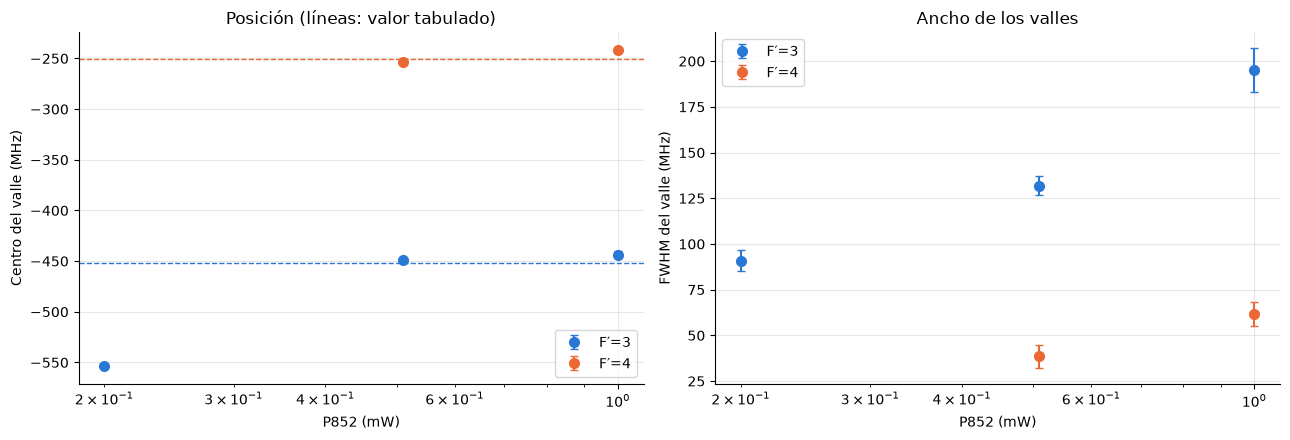

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
Pd = np.array([r['P'] for r in resdip])
for F, col in ((3, C1), (4, C2)):
    ok = np.array([r[f'a{F}'] > 3*r[f'ea{F}'] for r in resdip])
    axs[0].errorbar(Pd[ok], [r[f'x{F}'] for r, o in zip(resdip, ok) if o],
                    yerr=[r[f'ex{F}'] for r, o in zip(resdip, ok) if o], fmt='o', ms=7, color=col, capsize=3,
                    label=f"F′={F}")
    axs[0].axhline(DET_FP[F], ls='--', color=col, lw=1)
    axs[1].errorbar(Pd[ok], [r[f'g{F}'] for r, o in zip(resdip, ok) if o],
                    yerr=[r[f'eg{F}'] for r, o in zip(resdip, ok) if o], fmt='o', ms=7, color=col, capsize=3,
                    label=f"F′={F}")
axs[0].set_ylabel('Centro del valle (MHz)')
axs[0].set_title('Posición (líneas: valor tabulado)')
axs[1].set_ylabel('FWHM del valle (MHz)')
axs[1].set_title('Ancho de los valles')
for ax in axs:
    ax.set_xscale('log')
    ax.set_xlabel('P852 (mW)')
    ax.legend()
fig.tight_layout()
plt.show()

## 4. Con y sin 822: efecto de la semilla sobre la fluorescencia de dos fotones

Las dos series se tomaron con las mismas potencias del 852 (510 µW frente a 503 µW en la toma más cercana) y el medidor de onda da frecuencias absolutas, así que se pueden restar sobre un eje común. Se interpola el barrido del 852 solo sobre los bins del barrido con el 822 y se calcula

$$\Delta S(\nu_{852}) = S_{822+852} - S_{852}.$$

Si las dos contribuciones fueran independientes, $\Delta S$ sería plano y estaría al nivel de la fluorescencia del 822 solo. Lo que se aparta de eso es el efecto del 852 sobre la población de 8S.

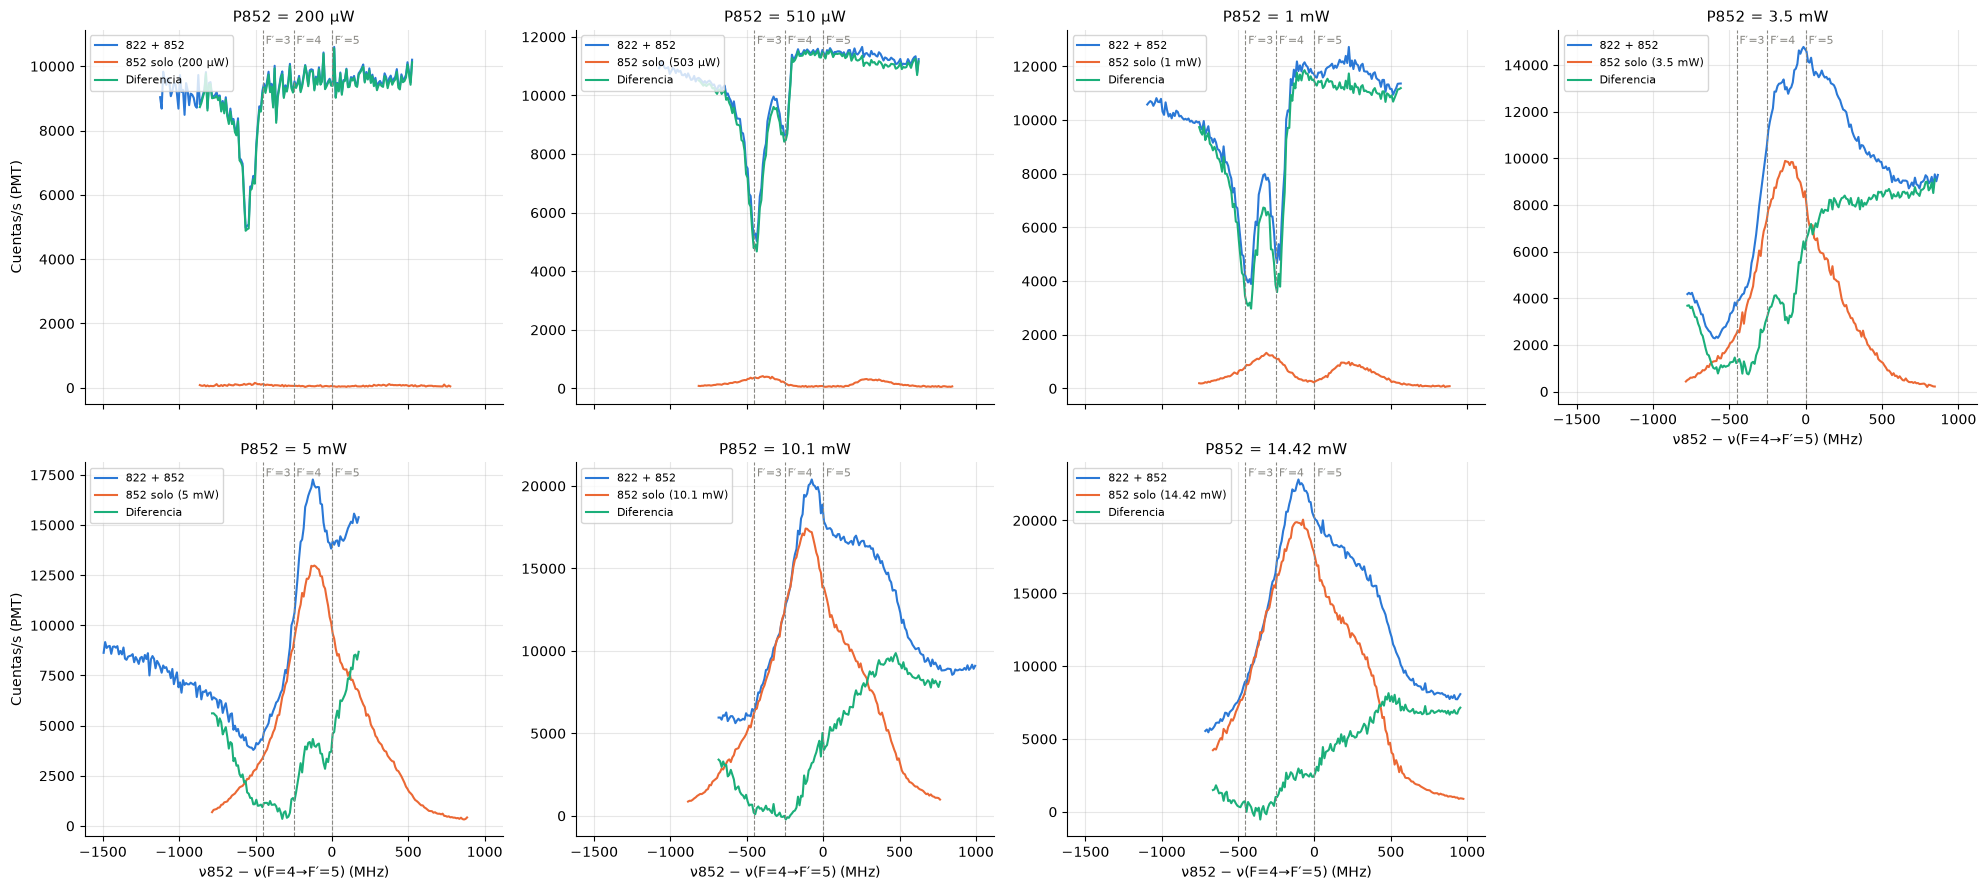

In [9]:
avg852 = {}
for f in F852:
    meta, d, segs, x, m, s = scan(f)
    avg852[meta['P']] = (x, m)

fig, axs = plt.subplots(2, 4, figsize=(20, 9), sharex=True)
for ax, f in zip(axs.flat, FCOMB):
    meta, d, segs, x, m, s = scan(f)
    Ps = min(avg852, key=lambda p: abs(p - meta['P']))
    xs, ms = avg852[Ps]
    ov = (x >= xs.min()) & (x <= xs.max())
    m852 = np.interp(x[ov], xs, ms)
    ax.plot(x, m, '-', lw=1.5, color=C1, label='822 + 852')
    ax.plot(xs, ms, '-', lw=1.5, color=C2, label=f'852 solo ({label(dict(P=Ps))})')
    ax.plot(x[ov], m[ov] - m852, '-', lw=1.5, color=C3, label='Diferencia')
    mark_Fp(ax)
    ax.set_title(f"P852 = {label(meta)}", fontsize=11)
    ax.legend(fontsize=8, loc='upper left')
axs.flat[-1].axis('off')
for ax in axs[:, 0]:
    ax.set_ylabel('Cuentas/s (PMT)')
for ax in list(axs[-1, :-1]) + [axs[0, -1]]:
    ax.xaxis.set_tick_params(labelbottom=True)
    ax.set_xlabel('ν852 − ν(F=4→F′=5) (MHz)')
fig.tight_layout()
plt.show()

## Resumen

- **822 solo:** el pico de dos fotones 6S F=4 → 8S F=4 tiene FWHM = 424 ± 2 MHz, contra 425.6 MHz de Doppler a 80 °C. El perfil es enteramente Doppler. El centro queda a +47 MHz de $\nu_{TP}/2$ tabulado (λ0 = 822.468822 nm), que es el corrimiento absoluto del medidor de onda. Las rampas de subida y de bajada se separan 21 MHz por la exposición de 200 ms, y el promedio de ambas lo cancela.
- **852 solo:** hasta 1 mW la línea D2 sale con autoabsorción (dos jorobas y un hueco en el centro), con una profundidad óptica efectiva hasta la región observada que baja de ≈ 7 a ≈ 3. Desde 3.5 mW la transición está saturada ($b = 0$) y el ancho crece de 474 a 677 MHz. La señal integrada crece como $P^{2.0}$ hasta 1 mW.
- **852 con el 822 fijo, ≤ 1 mW:** aparecen valles sub-Doppler de la clase $v_z \approx 0$ en F′=3 y F′=4, por bombeo óptico a F=3. En F′=5 (cíclica) no hay valle. Con 510 µW y 1 mW la separación entre valles es 195 ± 3 y 202 ± 4 MHz, frente a 201.3 MHz tabulados. Los valles se ensanchan con la potencia (F′=3: 91, 132 y 195 MHz).
  - A 200 µW solo se resuelve F′=3, corrido −108 MHz. Es compatible con que el 822 estuviera ≈ 110 MHz por debajo del máximo de dos fotones, pero en esa toma no hay registro del 822 para comprobarlo.
- **852 con el 822 fijo, ≥ 3.5 mW:** domina la fluorescencia del 852 solo. Al restarla, la fluorescencia de dos fotones queda casi suprimida entre ≈ −700 y −250 MHz, porque el 852 ensanchado por potencia vacía F=4 en todo ese intervalo. Esta lectura supone que las dos contribuciones se suman.
